# 01 – First Look at the Chicago Food Inspections Data 
**Input:** `Food_Inspections.csv`, downloaded from the Chicago Data Portal page "Food Inspections" (Export → CSV), put the CSV in this project folder; it is not uploaded to GitHub because it is too large (see `.gitignore`)

This notebook only looks at the raw data (size, columns, values, years, periods, violations)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

We import pandas (tables), numpy (numbers), matplotlib and seaborn (plots)

In [2]:
# read the dataset from the project folder
food = pd.read_csv('Food_Inspections.csv') #data from 1 Jan 2010 till 17 Oct 2026

We read the dataset from the project folder, it covers inspections from 1 January 2010 to 17 October 2026.

## 1. Size, columns and types

In [3]:
food.shape

(317175, 17)

The dataset has **317,175 rows** (inspections) and **17 columns**.

In [4]:
food.columns

Index(['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type',
       'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date',
       'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude',
       'Location'],
      dtype='str')

The 17 columns: IDs and names (Inspection ID, DBA Name, AKA Name, License #), the place (Facility Type, Risk, Address, City, State, Zip, Latitude, Longitude, Location), and the inspection itself (Inspection Date, Inspection Type, Results, Violations).

In [5]:
food.info()

<class 'pandas.DataFrame'>
RangeIndex: 317175 entries, 0 to 317174
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    317175 non-null  int64  
 1   DBA Name         317175 non-null  str    
 2   AKA Name         314751 non-null  str    
 3   License #        317156 non-null  float64
 4   Facility Type    311818 non-null  str    
 5   Risk             317088 non-null  str    
 6   Address          317175 non-null  str    
 7   City             316993 non-null  str    
 8   State            317099 non-null  str    
 9   Zip              317133 non-null  float64
 10  Inspection Date  317175 non-null  str    
 11  Inspection Type  317174 non-null  str    
 12  Results          317175 non-null  str    
 13  Violations       227682 non-null  str    
 14  Latitude         316113 non-null  float64
 15  Longitude        316113 non-null  float64
 16  Location         316113 non-null  str    
dtypes:

Most columns are text (str). Inspection ID is an integer; License #, Zip, Latitude and Longitude are float (decimal) numbers. Inspection Date is still text here; we turn it into a real date later.

In [6]:
food.describe()

,Inspection ID,License #,Zip,Latitude,Longitude
count,3.171750e+05,3.171560e+05,317133.000000,316113.000000,316113.000000
mean,1.868536e+06,1.807529e+06,60628.793232,41.880563,-87.676373
std,7.351689e+05,9.494890e+05,199.934815,0.080860,0.058435
min,4.424700e+04,0.000000e+00,10014.000000,41.644670,-87.906874
25%,1.375654e+06,1.472957e+06,60614.000000,41.831831,-87.707373
50%,2.088877e+06,2.103360e+06,60625.000000,41.891728,-87.666350
75%,2.559286e+06,2.463316e+06,60643.000000,41.939475,-87.634874
max,2.645351e+06,9.999999e+06,91706.000000,42.021064,-87.525094


`describe()` only summarizes the numeric columns, these are mostly IDs and coordinates, so the mean and std have no real meaning, but we can see two problems: License # has a minimum of **0** (not a real license) and a maximum of 9,999,999, and some Zip codes (min 10014, max 91706) are outside Chicago (606xx)

In [7]:
# missing values in each column
food.isnull().sum()

Inspection ID          0
DBA Name               0
AKA Name            2424
License #             19
Facility Type       5357
Risk                  87
Address                0
City                 182
State                 76
Zip                   42
Inspection Date        0
Inspection Type        1
Results                0
Violations         89493
Latitude            1062
Longitude           1062
Location            1062
dtype: int64

Missing values per column, **Violations** has the most (89,493): an empty Violations text usually means the inspector found nothing, Facility Type (5,357), AKA Name (2,424) and the location columns (1,062) also have missing values, License # is missing in 19 rows and Inspection Type in 1 row.

In [8]:
food.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2645329,LA MICHOACANA,LA MICHOACANA,3104395.0,Restaurant,Risk 1 (High),2740 W 59TH ST,CHICAGO,IL,60629.0,10/16/2026,License,Pass,58. ALLERGEN TRAINING AS REQUIRED - Comments: ...,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)"
1,2645351,IRON CAFE,IRON CAFE,2993280.0,Restaurant,Risk 2 (Medium),3700 S IRON ST,CHICAGO,IL,60609.0,10/16/2026,License,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.826881,-87.659475,"(41.82688091287133, -87.65947456175756)"
2,2645334,Dewey,Dewey,22951.0,School,Risk 1 (High),5415 S Union(700W) AVE,CHICAGO,IL,60609.0,10/16/2026,Canvass,Pass,NaN,NaN,NaN,NaN
3,2645326,MICHOACANA SWEETS,MICHOACANA SWEETS,2961261.0,Restaurant,Risk 2 (Medium),2740 W 59TH ST,CHICAGO,IL,60629.0,10/16/2026,Canvass,Out of Business,NaN,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)"
4,2645333,Stepping Stones Nursery School,Stepping Stones Nursery School,3016043.0,Children's Services Facility,Risk 1 (High),2750 W LAWRENCE AVE,CHICAGO,IL,60625.0,10/16/2026,License Re-Inspection,Pass,NaN,41.968645,-87.698217,"(41.96864515206485, -87.69821695287187)"


The first rows. The newest inspections (October 2026) are at the top. The Violations column is a long text with the violation number, title and the inspector's comments.

## 2. What values do the main columns have?

In [9]:
# all the different results (we will keep only Pass, Pass w/ Conditions, Fail)
food['Results'].value_counts()

Results
Pass                    164200
Fail                     61081
Pass w/ Conditions       47005
Out of Business          25941
No Entry                 14215
Not Ready                 4637
Business Not Located        96
Name: count, dtype: int64

There are 7 different results, Only **Pass (164,200), Fail (61,081) and Pass w/ Conditions (47,005)** are real inspections, out of Business (25,941), No Entry (14,215), Not Ready (4,637) and Business Not Located (96) mean the food was not checked, so we remove them in the cleaning.

In [10]:
food['Risk'].value_counts()

Risk
Risk 1 (High)      236126
Risk 2 (Medium)     56262
Risk 3 (Low)        24610
All                    90
Name: count, dtype: int64

Most places are Risk 1 (High) (236,126), then Risk 2 (56,262) and Risk 3 (24,610). 90 rows have "All", which is not a real risk level.

In [11]:
# 15 most common facility types
food['Facility Type'].value_counts().head(15)

Facility Type
Restaurant                         215179
Grocery Store                       38007
School                              19849
Children's Services Facility         7813
Bakery                               4560
Daycare Above and Under 2 Years      4206
Daycare (2 - 6 Years)                3266
Long Term Care                       2438
Catering                             1960
Liquor                               1372
Mobile Food Preparer                 1324
Hospital                              987
Mobile Food Dispenser                 967
Golden Diner                          894
Daycare Combo 1586                    627
Name: count, dtype: int64

Restaurants are by far the most common facility type (215,179), then grocery stores (38,007) and schools (19,849). Many types have only a few rows; later we group the small ones into "Other".

In [12]:
# 15 most common inspection types
food['Inspection Type'].value_counts().head(15)

Inspection Type
Canvass                     163664
License                      42569
Canvass Re-Inspection        35320
Complaint                    30106
License Re-Inspection        12868
Complaint Re-Inspection      12647
Short Form Complaint          9346
Non-Inspection                5744
Suspected Food Poisoning      1028
Consultation                   679
License-Task Force             604
Tag Removal                    603
Recent Inspection              544
Out of Business                284
Task Force Liquor 1475         252
Name: count, dtype: int64

Canvass (routine) inspections are the most common (163,664), then License (42,569) and Canvass Re-Inspection (35,320), Re-inspections are the follow-up visits after a fail; this becomes important in the cleaning and feature notebooks.

In [13]:
food['State'].dropna().unique()

<StringArray>
['IL', 'DC', 'IN', 'CA', 'WI', 'CO', 'NY']
Length: 7, dtype: str

Almost all inspections are in **IL** (Illinois, where Chicago is). The few other states (DC, IN, CA, WI, CO, NY) are probably address errors.

## 3. Dates: how many inspections per year?

In [14]:
# turn the date text (MM/DD/YYYY) into a real date, then take the year
# (pd.to_datetime is the standard pandas way to read dates)
food['Inspection Date'] = pd.to_datetime(food['Inspection Date'])
food['Year'] = food['Inspection Date'].dt.year
food['Year'].value_counts().sort_index()

Year
2010    18068
2011    18747
2012    18866
2013    20947
2014    21540
2015    20911
2016    22818
2017    21587
2018    17192
2019    19052
2020    15123
2021    15868
2022    16936
2023    18261
2024    19228
2025    19205
2026    12826
Name: count, dtype: int64

We turn the date text into a real date and take the year, 2018 (17,192) has fewer inspections than the years before (about 21,000–22,800), and 2020 has the fewest (15,123) because of COVID, 2026 is only until October.

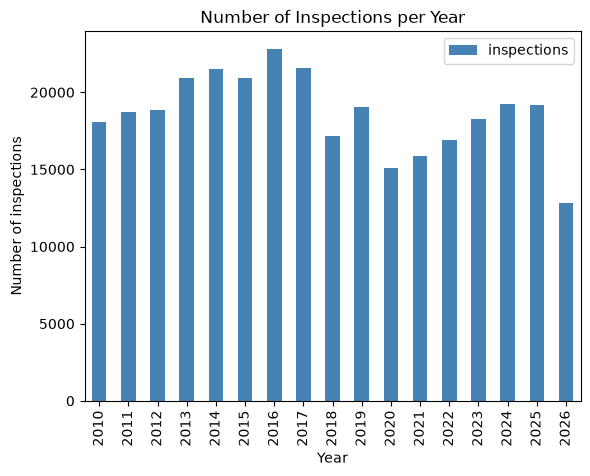

In [15]:
food['Year'].value_counts().sort_index().plot.bar(color='steelblue', label='inspections')
plt.title('Number of Inspections per Year')
plt.xlabel('Year')
plt.ylabel('Number of inspections')
plt.legend()
plt.show()

The same numbers as a bar chart: a clear drop in 2018 (the year of the new food code) and in 2020 (COVID).

In [16]:
food[food['Results'] == 'Out of Business'].groupby('Year')['Results'].count()

Year
2010     676
2011    1147
2012    2592
2013    3167
2014    2150
2015    1879
2016    1546
2017    1504
2018    1193
2019    1443
2020    1399
2021    1246
2022    1278
2023    1305
2024    1437
2025    1284
2026     695
Name: Results, dtype: int64

Out of Business results per year: most in 2012–2013 (2,592 and 3,167), then about 1,200–1,900 per year.

## 4. Do the results change over the years? (first sign of the 2018 change)

In [17]:
# keep only real inspection results
real = food[food['Results'].isin(['Pass', 'Pass w/ Conditions', 'Fail'])]
print('Rows before:', len(food), ' Rows with a real result:', len(real))

Rows before: 317175  Rows with a real result: 272286


We keep only the real results (Pass, Pass w/ Conditions, Fail): **272,286** of 317,175 rows.

In [18]:
# share of each result in each year (each row adds up to 1)
ct = pd.crosstab(real['Year'], real['Results'])
year_share = ct.divide(ct.sum(axis='columns'), axis='rows')
year_share

Results,Fail,Pass,Pass w/ Conditions
Year,,,
2010,0.259061,0.658958,0.081981
2011,0.247668,0.666117,0.086215
2012,0.227369,0.677051,0.095580
2013,0.196215,0.700961,0.102824
2014,0.199721,0.676279,0.124000
2015,0.201598,0.677789,0.120613
2016,0.216415,0.650957,0.132628
2017,0.222769,0.661603,0.115628
2018,0.223449,0.429052,0.347498


Share of each result per year (each row adds up to 1), Before 2018, Pass w/ Conditions is about 8–13%, in **2018 it jumps to 34.7% and in 2019 to 49.3%**, while Pass drops from about 66% to 28%, The Fail share stays around 20–25% every year.

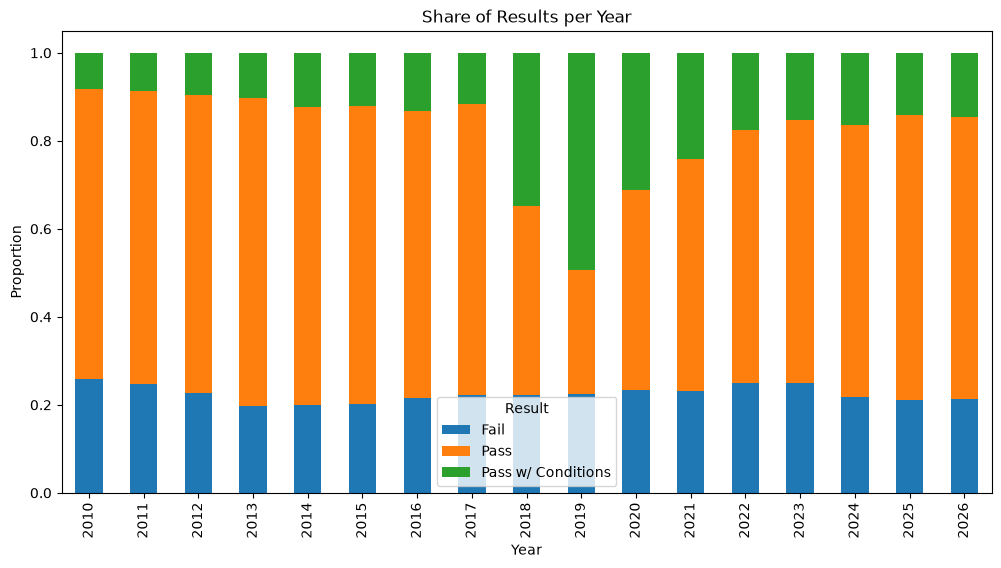

In [19]:
year_share.plot.bar(stacked=True, figsize=(12, 6))
plt.title('Share of Results per Year')
plt.xlabel('Year')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

The stacked bar chart shows the same thing: the orange (Pass) part shrinks and the green (Pass w/ Conditions) part grows a lot in 2018–2019, then slowly goes back toward the old pattern by 2022, Fail stays almost the same.

## 5. Periods: before, transition, after the July 2018 change

In [20]:
def get_period(date):
    if date < pd.Timestamp('2018-07-01'):
        return 'Pre'
    elif date < pd.Timestamp('2019-07-01'):
        return 'Transition'
    else:
        return 'Post'

real = real.copy()
real['Period'] = real['Inspection Date'].apply(get_period)
real['Period'].value_counts()

Period
Pre           151220
Post          106307
Transition     14759
Name: count, dtype: int64

We label each inspection by period: Pre (before 1 July 2018), Transition (1 July 2018 – 30 June 2019) and Post (after), Pre has 151,220 inspections, Transition 14,759 and Post 106,307.

In [21]:
ct_period = pd.crosstab(real['Period'], real['Results'])
ct_period.divide(ct_period.sum(axis='columns'), axis='rows')

Results,Fail,Pass,Pass w/ Conditions
Period,,,
Post,0.229769,0.563359,0.206873
Pre,0.221756,0.669019,0.109225
Transition,0.211464,0.212887,0.575649


Share of results per period, **Pass w/ Conditions: 10.9% Pre → 57.6% Transition → 20.7% Post** Pass: 66.9% → 21.3% → 56.3%, Fail stays about the same (22.2% → 21.1% → 23.0%), So the change mainly moved inspections from Pass to Pass w/ Conditions, especially during the transition year.

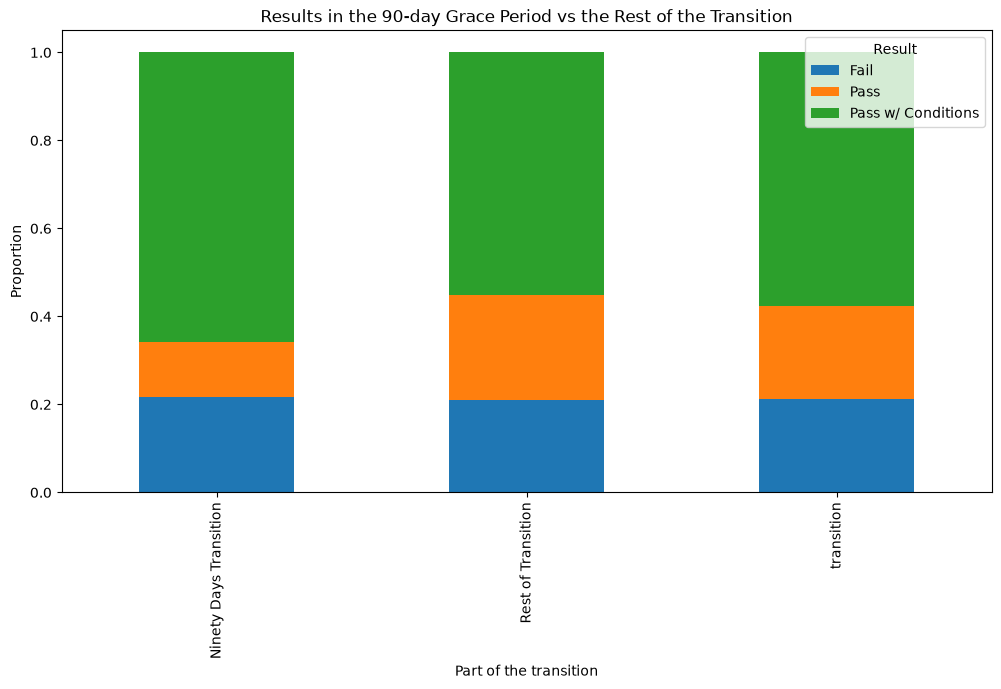

In [22]:
ninty_days_transition = real[(real['Inspection Date'] >= '2018-07-01') & (real['Inspection Date'] < '2018-10-01')]
rest_of_transition = real[(real['Inspection Date'] >= '2018-10-01') & (real['Inspection Date'] < '2019-07-01')]
comparison = pd.DataFrame({"Ninety Days Transition": ninty_days_transition['Results'].value_counts(normalize=True),
                          "Rest of Transition": rest_of_transition['Results'].value_counts(normalize=True),
                          "transition": real[real['Period'] == 'Transition']['Results'].value_counts(normalize=True)})
comparison.transpose().plot.bar(stacked=True, figsize=(12, 6))
plt.title('Results in the 90-day Grace Period vs the Rest of the Transition')
plt.xlabel('Part of the transition')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

We split the transition year into the first 90 days (the grace period: no fines, 90 days to comply) and the rest, and compare them in a stacked bar chart.

In [23]:
comparison

,Ninety Days Transition,Rest of Transition,transition
Results,,,
Fail,0.217288,0.209736,0.211464
Pass,0.124038,0.239258,0.212887
Pass w/ Conditions,0.658674,0.551006,0.575649


In the first 90 days only **12.4%** of inspections were a clean Pass, compared to **23.9%** in the rest of the transition year; Pass w/ Conditions was 65.9% vs 55.1%, Fail was almost the same (21.7% vs 21.0%), during the grace period inspectors wrote down many violations, but restaurants were not fined, so many got Pass w/ Conditions instead of a clean Pass.

In [24]:
ninty_days_transition = real[(real['Inspection Date'] >= '2018-07-01') & (real['Inspection Date'] < '2018-10-01')]
rest_of_transition = real[(real['Inspection Date'] >= '2018-10-01') & (real['Inspection Date'] < '2019-07-01')]
comparison = pd.DataFrame({"Before Transition": real[real['Period'] == 'Pre']['Results'].value_counts(normalize=True),
                          "Ninety Days Transition": ninty_days_transition['Results'].value_counts(normalize=True),
                          "Rest of Transition": rest_of_transition['Results'].value_counts(normalize=True),
                          "Full Transition": real[real['Period'] == 'Transition']['Results'].value_counts(normalize=True),
                          "After Transition": real[real['Period'] == 'Post']['Results'].value_counts(normalize=True)})
comparison.round(3)

,Before Transition,Ninety Days Transition,Rest of Transition,Full Transition,After Transition
Results,,,,,
Fail,0.222,0.217,0.210,0.211,0.230
Pass,0.669,0.124,0.239,0.213,0.563
Pass w/ Conditions,0.109,0.659,0.551,0.576,0.207


The same comparison with Pre and Post added, so we can see all five periods side by side.

In [25]:
real.groupby('State')['Results'].value_counts(normalize=True).unstack().round(2)

Results,Fail,Pass,Pass w/ Conditions
State,,,
CA,NaN,0.50,0.50
DC,NaN,NaN,1.00
IL,0.22,0.60,0.17
IN,0.23,0.77,NaN
NY,NaN,NaN,1.00
WI,NaN,0.33,0.67


Results by state, only IL has a meaningful number of inspections; the other states have only a few rows each, so their shares (like 100%) mean nothing.

## 6. Violations text

In [26]:
# look at one full violations text to see its format
print(real['Violations'].dropna().iloc[0])

58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.


One full Violations text: the violation number and title ("58. ALLERGEN TRAINING AS REQUIRED"), then "- Comments:" and the inspector's comment.

In [27]:
# one violation before and one after the change, to compare the numbering
print('BEFORE:', real[real['Period'] == 'Pre']['Violations'].dropna().iloc[0][:300])
print()
print('AFTER :', real[real['Period'] == 'Post']['Violations'].dropna().iloc[0][:300])

BEFORE: 32. FOOD AND NON-FOOD CONTACT SURFACES PROPERLY DESIGNED, CONSTRUCTED AND MAINTAINED - Comments: RUBBER  GASKET ON THE DOOR OF ONE OF THE CHEST FREEZER IN THE KITCHEN FIRST FLOOR WORN OUT/RIPPED OFF. MUST REPAIR/REPLACE AND MAINTAIN.  BOTH CHEST FREEZER IN THE KITCHEN FIRST FLOOR WITH HEAVY ICE ACCU

AFTER : 58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.


One violation before and one after the change, Before, the number 32 is "FOOD AND NON-FOOD CONTACT SURFACES…"; after, the numbers and titles are different ("58. ALLERGEN TRAINING…"), the same number does not mean the same thing before and after 2018.

In [28]:
# number of violations per inspection: the violations are separated by ' | '
# empty text (no violations) = 0
def count_violations(text):
    if pd.isnull(text):
        return 0
    else:
        return text.count(' | ') + 1

real['Num_Violations'] = real['Violations'].apply(count_violations)
real['Num_Violations'].describe()

count    272286.000000
mean          3.753366
std           3.371156
min           0.000000
25%           1.000000
50%           3.000000
75%           5.000000
max          40.000000
Name: Num_Violations, dtype: float64

Violations are separated by " | ", so the number of violations = number of separators + 1 (0 if empty), on average an inspection has **3.75 violations**, the median is 3 and the maximum is 40.

In [29]:
examples = list(real['Violations'].dropna().head())
examples

['58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.',
 '10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: Pre area hand wash sink in poor repair, Broken hot water knob, unable to shut off water. Instructed to repair. | 36. THERMOMETERS PROVIDED & ACCURATE - Comments: No metal stem thermometer, instructed to obtain. | 48. WAREWASHING FACILITIES: INSTALLED, MAINTAINED & USED; TEST STRIPS - Comments: No irreversible thermometer for high temp dish machine, instructed to obtain.',
 '16. FOOD-CONTACT SURFACES: CLEANED & SANITIZED - Comments: OBSERVED LARGE MIXING EQUIPMENT IN NEED OF SOME CLEANING TO REMOVE DEBRIS. | 49. NON-FOOD/FOOD CONTACT SURFACES CLEAN - Comments: OBSERVED FOOD DEBRIS ON INTERIOR AND EXTERIOR SURACES OF COOKING EQUIPMENT, DISPLAY CASES, SHELVING UNITS, PREP TABLES, COOLERS. ALSO DEFROST AND CLEAN THE INTER

The first five violation texts to see how several violations are joined with " | "

In [30]:
real.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Period,Num_Violations
0,2645329,LA MICHOACANA,LA MICHOACANA,3104395.0,Restaurant,Risk 1 (High),2740 W 59TH ST,CHICAGO,IL,60629.0,2026-10-16,License,Pass,58. ALLERGEN TRAINING AS REQUIRED - Comments: ...,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)",2026,Post,1
1,2645351,IRON CAFE,IRON CAFE,2993280.0,Restaurant,Risk 2 (Medium),3700 S IRON ST,CHICAGO,IL,60609.0,2026-10-16,License,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.826881,-87.659475,"(41.82688091287133, -87.65947456175756)",2026,Post,3
2,2645334,Dewey,Dewey,22951.0,School,Risk 1 (High),5415 S Union(700W) AVE,CHICAGO,IL,60609.0,2026-10-16,Canvass,Pass,NaN,NaN,NaN,NaN,2026,Post,0
4,2645333,Stepping Stones Nursery School,Stepping Stones Nursery School,3016043.0,Children's Services Facility,Risk 1 (High),2750 W LAWRENCE AVE,CHICAGO,IL,60625.0,2026-10-16,License Re-Inspection,Pass,NaN,41.968645,-87.698217,"(41.96864515206485, -87.69821695287187)",2026,Post,0
5,2645339,MAXI BAKERY,MAXI BAKERY,2659225.0,Bakery,Risk 1 (High),8712 S COMMERCIAL AVE,CHICAGO,IL,60617.0,2026-10-16,Canvass,Pass,16. FOOD-CONTACT SURFACES: CLEANED & SANITIZED...,41.736947,-87.551568,"(41.736946606132356, -87.55156773617517)",2026,Post,3


The first rows of `real` with the new Year, Period and Num_Violations columns.

In [31]:
real.iloc[1].Violations

'10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: Pre area hand wash sink in poor repair, Broken hot water knob, unable to shut off water. Instructed to repair. | 36. THERMOMETERS PROVIDED & ACCURATE - Comments: No metal stem thermometer, instructed to obtain. | 48. WAREWASHING FACILITIES: INSTALLED, MAINTAINED & USED; TEST STRIPS - Comments: No irreversible thermometer for high temp dish machine, instructed to obtain.'

The violations of the second inspection: 3 violations (10 hand-washing sink, 36 thermometers, 48 warewashing), separated by " | ".

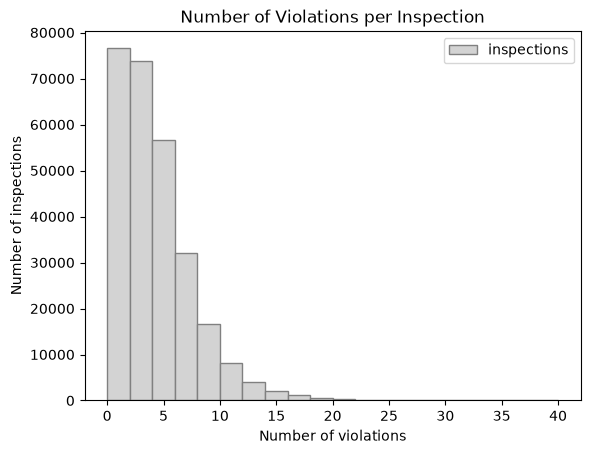

In [32]:
real['Num_Violations'].plot(kind='hist', bins=20, color='lightgray', edgecolor='grey', label='inspections')
plt.title('Number of Violations per Inspection')
plt.xlabel('Number of violations')
plt.ylabel('Number of inspections')
plt.legend()
plt.show()

Most inspections have 0–6 violations; the histogram has a long tail to the right (a few inspections with 20+ violations)

In [33]:
real[real['Num_Violations'] > 30].groupby('Period')['Num_Violations'].count()

Period
Post          6
Transition    2
Name: Num_Violations, dtype: int64

Inspections with more than 30 violations: 6 in Post and 2 in Transition, none in Pre.

In [34]:
real['Num_Violations'].value_counts().sort_index()

Num_Violations
0     45511
1     31020
2     36970
3     36744
4     31705
5     24927
6     18733
7     13402
8      9710
9      6837
10     4761
11     3381
12     2449
13     1658
14     1224
15      901
16      616
17      485
18      369
19      263
20      190
21      144
22       77
23       73
24       39
25       24
26       23
27       18
28        9
29        9
30        6
31        1
33        3
34        2
35        1
40        1
Name: count, dtype: int64

How many inspections have each number of violations? 45,511 have 0 violations; the numbers drop quickly after 5, and only a handful have more than 30.

In [35]:
real[real['Num_Violations'] >= 35]['Year'].value_counts()

Year
2025    1
2023    1
Name: count, dtype: int64

The two inspections with 35 or more violations are in 2023 and 2025.

In [36]:
real[real['Num_Violations'] > 15].groupby('Period')['Num_Violations'].count()

Period
Post          1686
Pre            106
Transition     561
Name: Num_Violations, dtype: int64

Inspections with more than 15 violations: **106 in Pre, 561 in Transition and 1,686 in Post**, long violation lists are much more common after the change.

In [37]:
real[real['Period'] == 'Pre']['Num_Violations'].max()

np.int64(23)

Before the change the maximum was **23** violations in one inspection.

In [38]:
real['Num_Violations'].max()

np.int64(40)

In the whole dataset the maximum is **40** violations.

In [39]:
real[(real['Num_Violations'] == 23) & (real['Period'] == 'Pre')]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Period,Num_Violations
236252,1115232,RACINE BAKERY INC,RACINE BAKERY INC,15456.0,Bakery,Risk 1 (High),6216 S ARCHER AVE,CHICAGO,IL,60638.0,2014-03-27,Complaint,Pass w/ Conditions,"6. HANDS WASHED AND CLEANED, GOOD HYGIENIC PRA...",41.793838,-87.775305,"(41.79383817679765, -87.77530511023124)",2014,Pre,23


The only Pre inspection with 23 violations: RACINE BAKERY INC (March 2014), result Pass w/ Conditions.

In [40]:
real[(real['Num_Violations'] >= 20) & (real['Num_Violations'] <= 30)].groupby('Results')['Num_Violations'].count()

Results
Fail                  521
Pass                    3
Pass w/ Conditions     88
Name: Num_Violations, dtype: int64

Inspections with 20–30 violations: most of them are Fail (521), 88 are Pass w/ Conditions and only 3 are Pass.

In [41]:
real[(real['Num_Violations'] >= 20) & (real['Num_Violations'] <= 30)].groupby('Period')['Num_Violations'].count()

Period
Post          434
Pre             8
Transition    170
Name: Num_Violations, dtype: int64

And most of these inspections (434 of 612) are in Post, only 8 in Pre, the new code produces longer violation lists.

In [42]:
# average number of violations for each result
real.groupby('Results')['Num_Violations'].mean()

Results
Fail                  6.252550
Pass                  2.392326
Pass w/ Conditions    5.260228
Name: Num_Violations, dtype: float64

Average number of violations per result: Fail 6.25, Pass w/ Conditions 5.26, Pass 2.39. More violations go with worse results

In [43]:
after = real[real['Inspection Date'] >= '2018-07-01']['Violations'].dropna()
titles = []
for text in after:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

violations = sorted(pd.Series(titles).unique())
df = pd.DataFrame({'Violations': violations})
df.to_csv('violations_titles_after.csv', index=False)
df.head()

,Violations
0,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW..."
1,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...
2,11. FOOD OBTAINED FROM APPROVED SOURCE
3,12. FOOD RECEIVED AT PROPER TEMPERATURE
4,"13. FOOD IN GOOD CONDITION, SAFE, & UNADULTERATED"


We collect every violation title written after 1 July 2018 (the part before " - Comments") and save the list of unique titles as `violations_titles_after.csv`

In [44]:
after = real[real['Inspection Date'] >= '2018-07-01']['Violations'].dropna()
titles = []
for text in after:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

v_nums = []
for v in pd.Series(titles).unique():
    v_nums.append(int(v.split('.')[0]))

max(v_nums)

64

After the change there are **64** different violation numbers (1 to 64)

In [45]:
before = real[real['Inspection Date'] < '2018-07-01']['Violations'].dropna()
titles = []
for text in before:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

v_nums = []
for v in pd.Series(titles).unique():
    v_nums.append(int(v.split('.')[0]))

sorted(v_nums)

[1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 70]

Before the change the violation numbers are 1–45 plus 70 (no smoking), so **46** different violations.

In [46]:
before = real[real['Inspection Date'] < '2018-07-01']['Violations'].dropna()
titles = []
for text in before:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

violations = sorted(pd.Series(titles).unique())
df2 = pd.DataFrame({'Violations': violations})
df2.to_csv('violations_titles_before.csv', index=False)

We save the list of old violation titles as `violations_titles_before.csv`, comparing the two lists is how we built the old to new crosswalk in `03_Violations.ipynb`

## 7. Save a smaller working file (2015–2020)

In [47]:
work = real[(real['Year'] >= 2015) & (real['Year'] <= 2020)]
print(work.shape)
# work.to_csv('/content/drive/MyDrive/food_2015_2020.csv', index=False)

(99821, 20)


A first working file for 2015–2020, (In `02_Cleaning.ipynb` we changed the years to 2015–2022, so 2020 with COVID is not the only "after" year)

## 8. Our observations
1. Inspection ID shouldn't be used in the model training 
2. Results column has 4 other values beside Pass, Fail and Pass w/ Conditions, out of Business count is more than half those of Pass w/ Conditions, we gusse if any should be eliminated it should be based on the research question. 
3. Both number of inspection per year chart and share per year chart shows that there was somthing different in the regulation change period like for the inspection per year the number dropped at 2018 and for share per year the number of pass w/ conditions increased. we can say that the number of pass w/ conditions has became less and kind of more like the earlier years starting from 2022. somthing else nice to mention that the number of inspections also dropped at 2020.
4. The higher number of violations per inspection (possible outliers) are mostly at and after the transition period with the 24-40 violations per inspections. for pre transition the highest was 23